# Midterm 3 — Clasificación de comentarios de Evaluación Docente (SET)
**Sistemas Inteligentes** · Profesor: Jefferson Amado Peña Torres\n\n**Integrantes:** Esteban David Muñoz Bautista, Nicolás Carreño Tascón, Brayan Zuluaga, Juan Manuel Canchala Giménez

Objetivo: evaluar un modelo inicial de *Machine Learning* que clasifique la **polaridad** (`negativo`, `neutral`, `positivo`) de comentarios abiertos de estudiantes.
El notebook sigue los 7 pasos de la guía: (1) carga y exploración, (2) preprocesamiento, (3) división de datos, (4) representación vectorial,
(5) línea base, (6) ajuste de hiperparámetros y (7) evaluación final.

In [1]:
import ast, json, re, sys, time, unicodedata, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.preprocesamiento import LimpiadorTexto, EmbeddingTransformer, limpiar_texto, embed, EMB_NAME

SEED = 42
np.random.seed(SEED)
DATA_DIR = ROOT / "Dataset"
FIG_DIR = ROOT / "figuras"; FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR = ROOT / "modelos"; MODEL_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.12.6 | scikit-learn 1.9.1 | pandas 3.1.1


## 1. Carga y exploración del CSV

In [2]:
archivos = sorted(DATA_DIR.glob("feedback_curso_universitario*.csv"))
partes = []
for f in archivos:
    d = pd.read_csv(f, encoding="utf-8-sig")
    n0 = len(d)
    d = d[d["id"].astype(str) != "id"].copy()          # fila de encabezado repetida
    d["fuente"] = f.stem
    print(f"{f.name}: {n0} filas leídas, {n0 - len(d)} encabezado(s) duplicado(s) eliminados -> {len(d)}")
    partes.append(d)
raw = pd.concat(partes, ignore_index=True)
print("\nTotal:", raw.shape)
raw.head()

feedback_curso_universitario.csv: 194 filas leídas, 1 encabezado(s) duplicado(s) eliminados -> 193
feedback_curso_universitario2.csv: 406 filas leídas, 1 encabezado(s) duplicado(s) eliminados -> 405
feedback_curso_universitario3.csv: 22 filas leídas, 2 encabezado(s) duplicado(s) eliminados -> 20

Total: (618, 9)


,id,curso,feedback,polaridad_basica,grano_fino,emocion,aspectos,semestre,fuente
0,1,Sistemas opertativos,Es un curso muy interesante y bien organizado....,['positivo'],3,neutral,[],2024-1,feedback_curso_universitario
1,3,Sistemas opertativos,"El contenido fue bastante interesante, aunque ...",['neutral'],3,neutral,"[{""aspecto"": ""contenidos"", ""sentimiento"": ""pos...",2024-1,feedback_curso_universitario
2,4,Sistemas opertativos,"El contenido fue excelente y detallado, ayudan...",['positivo'],3,neutral,"[{""aspecto"": ""contenidos"", ""sentimiento"": ""pos...",2024-1,feedback_curso_universitario
3,5,Sistemas opertativos,"El horario fue justo, no me dejó demasiado tie...",['positivo'],3,neutral,"[{""aspecto"": ""contenidos"", ""sentimiento"": ""pos...",2024-1,feedback_curso_universitario
4,6,Sistemas opertativos,"En general, el curso ha sido bastante desafian...",['negativo'],3,neutral,"[{""aspecto"": ""contenidos"", ""sentimiento"": ""pos...",2024-1,feedback_curso_universitario


In [3]:
print("Columnas:", list(raw.columns))
print("\nFaltantes por columna:\n", raw.isna().sum())
print("\nComentarios vacíos:", (raw["feedback"].fillna("").str.strip() == "").sum())
print("Comentarios duplicados (texto exacto, normalizado a minúsculas):",
      raw["feedback"].str.strip().str.lower().duplicated().sum())
for c in ["polaridad_basica", "grano_fino", "emocion", "curso", "semestre"]:
    print(f"\n--- {c} ---"); print(raw[c].value_counts(dropna=False).to_string())

Columnas: ['id', 'curso', 'feedback', 'polaridad_basica', 'grano_fino', 'emocion', 'aspectos', 'semestre', 'fuente']

Faltantes por columna:
 id                  0
curso               0
feedback            0
polaridad_basica    0
grano_fino          0
emocion             0
aspectos            0
semestre            0
fuente              0
dtype: int64

Comentarios vacíos: 0
Comentarios duplicados (texto exacto, normalizado a minúsculas): 0

--- polaridad_basica ---
polaridad_basica
neutral             215
negativo            124
['negativo']         81
positivo             70
['positivo']         66
['neutral']          44
positiva             12
["['positivo']"]      5
['posicion']          1

--- grano_fino ---
grano_fino
3    612
4      5
5      1

--- emocion ---
emocion
neutral         610
sorpresa          2
alegría           2
enojo             1
miedo             1
tristeza          1
enfriamiento      1

--- curso ---
curso
Sistemas opertativos           145
Arquitectura del co

**Hallazgos de calidad**
- Cada archivo trae la fila de encabezado repetida (eliminada arriba).
- `polaridad_basica` mezcla formatos: `negativo`, `['negativo']`, `["['positivo']"]`, `positiva` y un valor inválido `['posicion']`.
- `grano_fino` y `emocion` son casi constantes (≈ 3 y `neutral`) → no sirven como variable objetivo.
- `aspectos` es una lista JSON multi-etiqueta (se deja para el proyecto final).
- No existe columna de autor/estudiante; ver paso 3.

In [4]:
def normalizar_polaridad(v):
    s = str(v).strip()
    for _ in range(3):                      # desanidar "['x']" y "[\"['x']\"]"
        try:
            p = ast.literal_eval(s)
            s = str(p[0] if isinstance(p, (list, tuple)) and p else p).strip()
        except Exception:
            break
    s = s.lower()
    return {"positiva": "positivo", "negativa": "negativo"}.get(s, s)

df = raw.copy()
df["polaridad"] = df["polaridad_basica"].map(normalizar_polaridad)
invalidas = ~df["polaridad"].isin(["negativo", "neutral", "positivo"])
print("Etiquetas inválidas descartadas:", df.loc[invalidas, "polaridad_basica"].tolist())
df = df[~invalidas].reset_index(drop=True)
df["curso"] = df["curso"].str.replace("opertativos", "operativos").str.strip()
df["n_palabras"] = df["feedback"].str.split().str.len()

def parse_aspectos(v):
    try: return [a["aspecto"].strip().lower() for a in json.loads(v)]
    except Exception: return []
df["aspectos_lista"] = df["aspectos"].map(parse_aspectos)

print("Dataset final:", df.shape)
print(df["polaridad"].value_counts().to_string())

Etiquetas inválidas descartadas: ["['posicion']"]
Dataset final: (617, 12)
polaridad
neutral     259
negativo    205
positivo    153


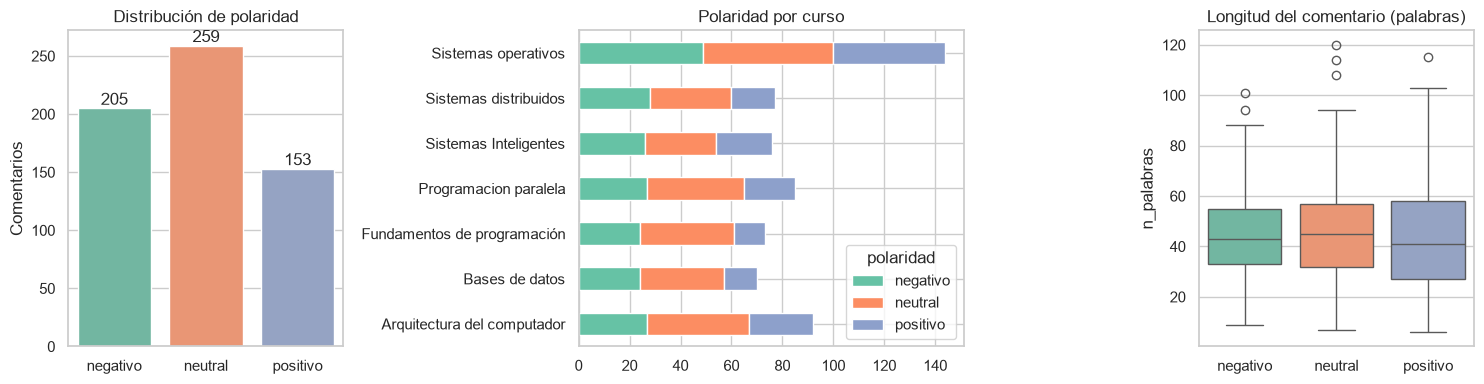

count    617.0
mean      45.1
std       19.1
min        6.0
25%       31.0
50%       44.0
75%       57.0
max      120.0


In [5]:
ORDEN = ["negativo", "neutral", "positivo"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1.4, 1]})
sns.countplot(data=df, x="polaridad", order=ORDEN, ax=ax[0], palette="Set2")
ax[0].set_title("Distribución de polaridad"); ax[0].set_xlabel(""); ax[0].set_ylabel("Comentarios")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
pd.crosstab(df["curso"], df["polaridad"])[ORDEN].plot(kind="barh", stacked=True, ax=ax[1], color=sns.color_palette("Set2"))
ax[1].set_title("Polaridad por curso"); ax[1].set_ylabel("")
sns.boxplot(data=df, x="polaridad", y="n_palabras", order=ORDEN, ax=ax[2], palette="Set2")
ax[2].set_title("Longitud del comentario (palabras)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_eda.png", dpi=200); plt.show()
print(df["n_palabras"].describe().round(1).to_string())

In [6]:
asp = df.explode("aspectos_lista")["aspectos_lista"].dropna().value_counts()
print("Aspectos distintos:", asp.size); print(asp.head(12).to_string())

Aspectos distintos: 22
aspectos_lista
contenidos                                           323
dificultad de las preguntas en los parciales          39
organización del curso y su planeación                35
diseño de las diapositivas                            34
material de clase                                     33
comentarios del profesor                              32
contenido y pertinencia                               31
parciales                                             30
diseño de la evaluación y criterios                   30
metodología del profesor                              30
disponibilidad de los recursos en el aula digital     28
retroalimentación de los examenes                     26


## 2. Definición de la tarea y preprocesamiento
**Tarea:** clasificación multiclase de un solo comentario → {negativo, neutral, positivo}. Métrica principal: **macro-F1** (las clases están desbalanceadas).

**Preprocesamiento** (dentro del `Pipeline` para que se aplique igual en entrenamiento e inferencia):
- minúsculas y normalización Unicode (se eliminan tildes para unificar variantes con/sin tilde),
- URLs, correos y números → tokens genéricos (anonimización básica),
- emojis → tokens `emo_pos` / `emo_neg`,
- **no** se eliminan negaciones ni intensificadores (`no`, `muy`, `nada`, `poco`, `bastante`), porque cambian la polaridad; además se marca la palabra siguiente a una negación (`no claro` → `no_claro`).

In [7]:
# limpiar_texto y LimpiadorTexto viven en src/preprocesamiento.py (reutilizables por la API/app)
for s in df["feedback"].sample(3, random_state=SEED):
    print("ORIGINAL :", s[:160]); print("LIMPIO   :", limpiar_texto(s)[:160], "\n")
print(limpiar_texto("El profe NO explica claro 😡 y el parcial 2 fue muy difícil 👎"))

ORIGINAL : El método de enseñanza fue bastante desafiante debido a la cantidad de material teórico. Sin embargo, el profesor siempre se mantuvo cercano y respondió rápidam
LIMPIO   : el metodo de ensenanza fue bastante desafiante debido a la cantidad de material teorico sin_embargo el profesor siempre se mantuvo cercano y respondio rapidamen 

ORIGINAL : El curso fue bastante neutro, no destacó mucho en ningún aspecto. Las lecciones eran organizadas, pero no me sentí animado con el contenido. La metodología del 
LIMPIO   : el curso fue bastante neutro no no_destaco mucho en ningun aspecto las lecciones eran organizadas pero no no_me senti animado con el contenido la metodologia de 

ORIGINAL : El diseño de las diapositivas fue claramente organizado y facilmente comprensible, lo cual contribuyó significativamente a mi aprendizaje. Los temas se presenta
LIMPIO   : el diseno de las diapositivas fue claramente organizado y facilmente comprensible lo cual contribuyo significativamente a mi 

## 3. División de datos
Partición **estratificada 80 % / 20 %** con semilla fija. El conjunto de prueba **no se usa** hasta el paso 7; toda selección de modelo se hace con validación cruzada sobre *train*.

> El CSV **no incluye identificador de autor**, por lo que no es posible agrupar por estudiante (`GroupKFold`). Se verificó que no hay comentarios duplicados entre archivos, lo que reduce el riesgo de fuga de información. Si en el proyecto final se dispone de un ID anónimo de estudiante, debe usarse `StratifiedGroupKFold`.

In [8]:
X = df["feedback"].to_numpy(dtype=object)   # numpy explícito: con pyarrow, .values devuelve un ArrowStringArray
y = df["polaridad"].to_numpy(dtype=object)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
resumen = pd.DataFrame({"train": pd.Series(y_train).value_counts(), "test": pd.Series(y_test).value_counts()}).loc[ORDEN]
resumen["% train"] = (100 * resumen["train"] / resumen["train"].sum()).round(1)
resumen["% test"] = (100 * resumen["test"] / resumen["test"].sum()).round(1)
print(f"Train: {len(X_train)} | Test: {len(X_test)}"); resumen

Train: 493 | Test: 124


,train,test,% train,% test
negativo,164,41,33.3,33.1
neutral,207,52,42.0,41.9
positivo,122,31,24.7,25.0


## 4. Representación vectorial del texto
Se comparan dos familias, **ajustadas solo con train** (dentro de cada fold de CV):
1. **TF-IDF** de palabras (1–2 gramas) + caracteres (3–5 gramas, robusto a errores ortográficos).
2. **Embeddings semánticos** de Hugging Face: `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` (multilingüe, 384 dimensiones). El modelo es preentrenado y no se ajusta con nuestros datos, por lo que no hay fuga.

In [9]:
# EmbeddingTransformer y embed() viven en src/preprocesamiento.py
t0 = time.time(); embed(list(X)); print(f"Embeddings calculados para {len(X)} textos en {time.time()-t0:.1f}s")

def tfidf():
    return FeatureUnion([
        ("pal", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("car", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
    ])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings calculados para 617 textos en 14.0s


## 5. Entrenamiento inicial y línea base
Validación cruzada **estratificada de 5 folds** sobre train. Se comparan `DummyClassifier` (referencia), Logistic Regression, Linear SVM, Naive Bayes y Random Forest con ambas representaciones.
(Naive Bayes: `MultinomialNB` para TF-IDF y `GaussianNB` para embeddings, que tienen valores negativos.)

In [10]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"macro_f1": "f1_macro", "accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro"}

def p_tfidf(clf):  return Pipeline([("limpiar", LimpiadorTexto()), ("vec", tfidf()), ("clf", clf)])
def p_emb(clf):    return Pipeline([("emb", EmbeddingTransformer()), ("clf", clf)])

clfs = {
    "Dummy (más frecuente)": lambda: DummyClassifier(strategy="most_frequent"),
    "Dummy (estratificado)": lambda: DummyClassifier(strategy="stratified", random_state=SEED),
    "Logistic Regression":   lambda: LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
    "Linear SVM":            lambda: LinearSVC(class_weight="balanced", random_state=SEED),
    "Naive Bayes":           None,
    "Random Forest":         lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
}
filas = []
for rep, builder in [("TF-IDF", p_tfidf), ("Embeddings", p_emb)]:
    for nombre, mk in clfs.items():
        clf = (MultinomialNB() if rep == "TF-IDF" else GaussianNB()) if mk is None else mk()
        r = cross_validate(builder(clf), X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1)
        filas.append({"Representación": rep, "Modelo": nombre,
                      "macro-F1": r["test_macro_f1"].mean(), "± sd": r["test_macro_f1"].std(),
                      "Accuracy": r["test_accuracy"].mean(), "Precision": r["test_precision"].mean(),
                      "Recall": r["test_recall"].mean()})
base = pd.DataFrame(filas).sort_values("macro-F1", ascending=False).reset_index(drop=True)
base.round(3)

,Representación,Modelo,macro-F1,± sd,Accuracy,Precision,Recall
0,Embeddings,Linear SVM,0.701,0.016,0.702,0.701,0.714
1,Embeddings,Logistic Regression,0.686,0.028,0.686,0.686,0.704
2,Embeddings,Random Forest,0.678,0.045,0.675,0.680,0.681
3,TF-IDF,Random Forest,0.648,0.055,0.653,0.651,0.650
4,Embeddings,Naive Bayes,0.640,0.016,0.639,0.638,0.655
5,TF-IDF,Logistic Regression,0.638,0.028,0.645,0.641,0.640
6,TF-IDF,Linear SVM,0.616,0.049,0.625,0.619,0.617
7,TF-IDF,Naive Bayes,0.428,0.058,0.530,0.724,0.459
8,Embeddings,Dummy (estratificado),0.335,0.058,0.361,0.334,0.336
9,TF-IDF,Dummy (estratificado),0.335,0.058,0.361,0.334,0.336


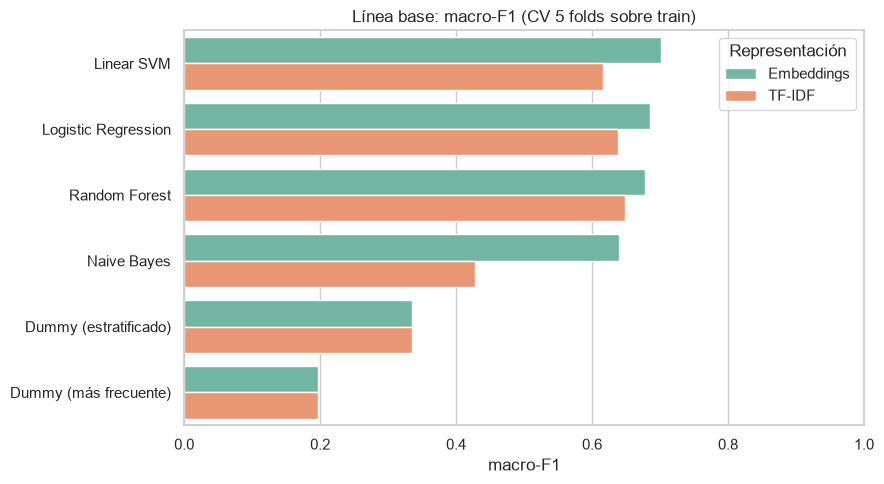

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=base, y="Modelo", x="macro-F1", hue="Representación", palette="Set2", ax=ax)
ax.set_title("Línea base: macro-F1 (CV 5 folds sobre train)"); ax.set_xlim(0, 1); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_linea_base.png", dpi=200); plt.show()

## 6. Ajuste de hiperparámetros
`Pipeline` + `GridSearchCV` con CV estratificada (5 folds), selección por **macro-F1**. Se ajustan Logistic Regression, Linear SVM y Naive Bayes con TF-IDF; Logistic Regression, Linear SVM y Random Forest con embeddings; y Logistic Regression con una representación híbrida (TF-IDF + embeddings).

In [12]:
def p_hibrido(clf):
    feats = FeatureUnion([
        ("tfidf", Pipeline([("limpiar", LimpiadorTexto()), ("vec", tfidf())])),
        ("emb", EmbeddingTransformer()),
    ])
    return Pipeline([("feats", feats), ("clf", clf)])

C_GRID = [0.01, 0.1, 0.5, 1, 2, 5, 10]
busquedas = {
    ("TF-IDF", "Logistic Regression"): (p_tfidf(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
        {"vec__pal__ngram_range": [(1, 1), (1, 2)], "vec__pal__min_df": [1, 2], "clf__C": C_GRID}),
    ("TF-IDF", "Linear SVM"): (p_tfidf(LinearSVC(class_weight="balanced", random_state=SEED)),
        {"vec__pal__ngram_range": [(1, 1), (1, 2)], "vec__pal__min_df": [1, 2], "clf__C": C_GRID}),
    ("TF-IDF", "Naive Bayes"): (p_tfidf(MultinomialNB()),
        {"vec__pal__ngram_range": [(1, 1), (1, 2)], "clf__alpha": [0.01, 0.05, 0.1, 0.5, 1.0]}),
    ("Embeddings", "Logistic Regression"): (p_emb(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
        {"clf__C": C_GRID}),
    ("Embeddings", "Linear SVM"): (p_emb(LinearSVC(class_weight="balanced", random_state=SEED)),
        {"clf__C": C_GRID}),
    ("Embeddings", "Random Forest"): (p_emb(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)),
        {"clf__n_estimators": [200, 500], "clf__max_depth": [None, 10, 20], "clf__min_samples_leaf": [1, 3]}),
    ("Híbrido", "Logistic Regression"): (p_hibrido(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
        {"clf__C": C_GRID}),
}
resultados, mejores = [], {}
for (rep, nom), (pipe, grid) in busquedas.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1_macro", n_jobs=1, refit=True).fit(X_train, y_train)
    i = gs.best_index_
    resultados.append({"Representación": rep, "Modelo": nom, "macro-F1 CV": gs.best_score_,
                       "± sd": gs.cv_results_["std_test_score"][i], "Combinaciones": len(gs.cv_results_["params"]),
                       "Mejores parámetros": gs.best_params_, "Tiempo (s)": round(time.time() - t0, 1)})
    mejores[(rep, nom)] = gs.best_estimator_
ajuste = pd.DataFrame(resultados).sort_values("macro-F1 CV", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", 120); ajuste.round(3)

,Representación,Modelo,macro-F1 CV,± sd,Combinaciones,Mejores parámetros,Tiempo (s)
0,Híbrido,Logistic Regression,0.711,0.044,7,{'clf__C': 1},11.3
1,Embeddings,Logistic Regression,0.707,0.020,7,{'clf__C': 2},0.7
2,Embeddings,Linear SVM,0.701,0.016,7,{'clf__C': 1},1.2
3,Embeddings,Random Forest,0.682,0.027,12,"{'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500}",28.6
4,TF-IDF,Logistic Regression,0.644,0.032,28,"{'clf__C': 0.5, 'vec__pal__min_df': 1, 'vec__pal__ngram_range': (1, 2)}",37.8
5,TF-IDF,Linear SVM,0.643,0.029,28,"{'clf__C': 0.1, 'vec__pal__min_df': 2, 'vec__pal__ngram_range': (1, 2)}",30.1
6,TF-IDF,Naive Bayes,0.605,0.032,10,"{'clf__alpha': 0.05, 'vec__pal__ngram_range': (1, 1)}",9.4


## 7. Evaluación final y comparación
Se evalúan sobre el **conjunto de prueba (20 %)**, una sola vez, los modelos ajustados. El modelo final se elige por macro-F1 en CV (no en test) para no sesgar la selección.

In [13]:
filas = []
for (rep, nom), est in mejores.items():
    p = est.predict(X_test)
    filas.append({"Representación": rep, "Modelo": nom, "Accuracy": accuracy_score(y_test, p),
                  "Precision (macro)": precision_score(y_test, p, average="macro", zero_division=0),
                  "Recall (macro)": recall_score(y_test, p, average="macro", zero_division=0),
                  "macro-F1": f1_score(y_test, p, average="macro")})
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train); pd_ = dummy.predict(X_test)
filas.append({"Representación": "—", "Modelo": "Dummy (más frecuente)", "Accuracy": accuracy_score(y_test, pd_),
              "Precision (macro)": precision_score(y_test, pd_, average="macro", zero_division=0),
              "Recall (macro)": recall_score(y_test, pd_, average="macro", zero_division=0),
              "macro-F1": f1_score(y_test, pd_, average="macro")})
test_tab = pd.DataFrame(filas).sort_values("macro-F1", ascending=False).reset_index(drop=True)
test_tab.round(3)

,Representación,Modelo,Accuracy,Precision (macro),Recall (macro),macro-F1
0,Embeddings,Logistic Regression,0.750,0.750,0.767,0.752
1,Embeddings,Random Forest,0.734,0.738,0.733,0.735
2,Embeddings,Linear SVM,0.718,0.719,0.731,0.720
3,Híbrido,Logistic Regression,0.718,0.713,0.721,0.714
4,TF-IDF,Linear SVM,0.669,0.678,0.653,0.661
5,TF-IDF,Naive Bayes,0.653,0.648,0.639,0.642
6,TF-IDF,Logistic Regression,0.645,0.638,0.634,0.636
7,—,Dummy (más frecuente),0.419,0.140,0.333,0.197


Modelo seleccionado (por CV): ('Híbrido', 'Logistic Regression') 
Parámetros: {'clf__C': 1} 

              precision    recall  f1-score   support

    negativo      0.755     0.902     0.822        41
     neutral      0.696     0.615     0.653        52
    positivo      0.690     0.645     0.667        31

    accuracy                          0.718       124
   macro avg      0.713     0.721     0.714       124
weighted avg      0.714     0.718     0.712       124



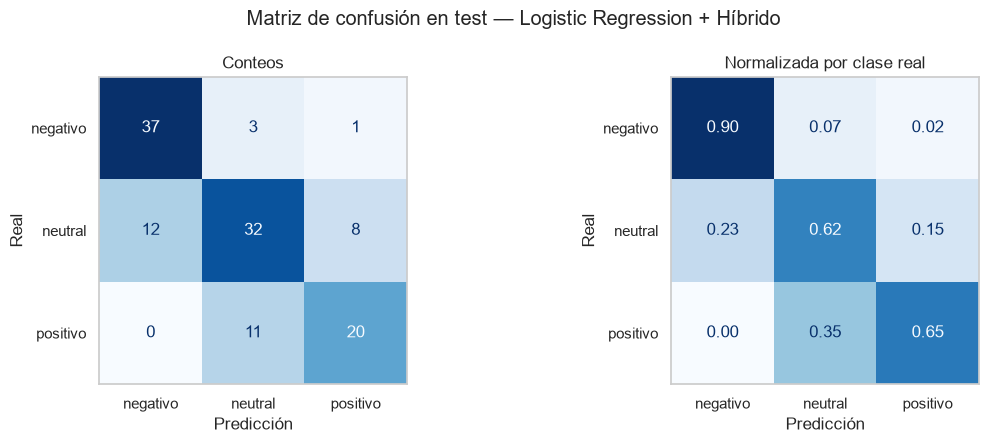

In [14]:
mejor_key = tuple(ajuste.loc[0, ["Representación", "Modelo"]])
modelo_final = mejores[mejor_key]
y_pred = modelo_final.predict(X_test)
print("Modelo seleccionado (por CV):", mejor_key, "\nParámetros:", ajuste.loc[0, "Mejores parámetros"], "\n")
print(classification_report(y_test, y_pred, labels=ORDEN, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, norm, tit in [(ax[0], None, "Conteos"), (ax[1], "true", "Normalizada por clase real")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=ORDEN, normalize=norm), display_labels=ORDEN).plot(
        ax=a, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
    a.grid(False); a.set_title(tit); a.set_xlabel("Predicción"); a.set_ylabel("Real")
fig.suptitle(f"Matriz de confusión en test — {mejor_key[1]} + {mejor_key[0]}")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_matriz_confusion.png", dpi=200); plt.show()

### Análisis de errores

In [15]:
err = pd.DataFrame({"comentario": X_test, "real": y_test, "pred": y_pred})
err = err[err["real"] != err["pred"]]
print(f"Errores: {len(err)} de {len(y_test)} ({100*len(err)/len(y_test):.1f} %)\n")
pares = err.groupby(["real", "pred"]).size().sort_values(ascending=False)
pares.rename("n").reset_index().to_csv(FIG_DIR / "tabla_errores.csv", index=False)
print(pares.to_string(), "\n")
for _, r in err.head(10).iterrows():
    print(f"[real={r.real} | pred={r.pred}] {r.comentario[:220]}\n")

Errores: 35 de 124 (28.2 %)

real      pred    
neutral   negativo    12
positivo  neutral     11
neutral   positivo     8
negativo  neutral      3
          positivo     1 

[real=positivo | pred=neutral] El curso tuvo contenidos interesantes y variados, pero el ritmo y la carga de trabajo fueron bastante intensos, lo cual generó cierto miedo y sorpresa por adaptarse a la nueva metodología. Además, la retroalimentación de

[real=positivo | pred=neutral] El horario fue bastante flexible y me permitió llevar mis estudios sin problemas. Todo estaba bien organizado y la material era relevante.

[real=positivo | pred=neutral] El material de clase fue muy completo y detallado. Me permitió entender los conceptos básicos y avanzados de forma clara. Sin embargo, algunas veces se complicaron los ejemplos y las aplicaciones prácticas podrían haber 

[real=neutral | pred=positivo] El horario me resultó conveniente ya que facilitaba mi organización personal. El diseño de las diapositivas era claro

### Palabras más influyentes (modelo interpretable TF-IDF + Logistic Regression)
Los embeddings no son interpretables palabra a palabra; para explicar qué aprende el modelo se usan los coeficientes del modelo TF-IDF ajustado.

In [16]:
m_tf = mejores[("TF-IDF", "Logistic Regression")]
uni = m_tf.named_steps["vec"]; clf = m_tf.named_steps["clf"]
nombres = np.array(uni.get_feature_names_out())
es_pal = np.char.startswith(nombres.astype(str), "pal__")
for i, c in enumerate(clf.classes_):
    coef = np.where(es_pal, clf.coef_[i], -np.inf)
    top = np.argsort(coef)[-12:][::-1]
    print(f"{c:>9}: ", ", ".join(n.split("__", 1)[1] for n in nombres[top]))

 negativo:  no, interesantes, las preguntas, en los, bastante desafiante, claridad, debido, pero la, dificil, desafiante, eran, la falta
  neutral:  neutral, algunas, bien, pero, bastante neutral, la ensenanza, en cuanto, cuanto, aunque algunas, pero tambien, algunas preguntas, fue util
 positivo:  fue muy, muy, mucho, un poco, excelente, gratificante, dinamico, ha, con la, me ha, satisfecho con, util


### Guardar modelo (insumo para el MVP del proyecto final)
Se guarda el `Pipeline` completo (limpieza + vectorizador + clasificador) con `joblib`, junto con metadatos de versión.

In [17]:
nombre_archivo = MODEL_DIR / "modelo_polaridad_v1.joblib"
joblib.dump(modelo_final, nombre_archivo)
meta = {"version": "v1", "representacion": mejor_key[0], "modelo": mejor_key[1],
        "parametros": {k: str(v) for k, v in ajuste.loc[0, "Mejores parámetros"].items()},
        "macro_f1_cv": round(float(ajuste.loc[0, "macro-F1 CV"]), 4),
        "macro_f1_test": round(float(f1_score(y_test, y_pred, average="macro")), 4),
        "accuracy_test": round(float(accuracy_score(y_test, y_pred)), 4),
        "n_train": int(len(X_train)), "n_test": int(len(X_test)), "clases": ORDEN,
        "dataset": [f.name for f in archivos], "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__, "embeddings": EMB_NAME if mejor_key[0] != "TF-IDF" else None}
(MODEL_DIR / "modelo_polaridad_v1.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(meta, indent=2, ensure_ascii=False))

# Exportar tablas para el artículo
base.round(3).to_csv(FIG_DIR / "tabla_linea_base.csv", index=False)
ajuste.round(3).to_csv(FIG_DIR / "tabla_ajuste.csv", index=False)
test_tab.round(3).to_csv(FIG_DIR / "tabla_test.csv", index=False)
pd.DataFrame(classification_report(y_test, y_pred, labels=ORDEN, output_dict=True)).T.round(3).to_csv(FIG_DIR / "tabla_reporte_final.csv")
resumen.to_csv(FIG_DIR / "tabla_split.csv")

{
  "version": "v1",
  "representacion": "Híbrido",
  "modelo": "Logistic Regression",
  "parametros": {
    "clf__C": "1"
  },
  "macro_f1_cv": 0.7113,
  "macro_f1_test": 0.714,
  "accuracy_test": 0.7177,
  "n_train": 493,
  "n_test": 124,
  "clases": [
    "negativo",
    "neutral",
    "positivo"
  ],
  "dataset": [
    "feedback_curso_universitario.csv",
    "feedback_curso_universitario2.csv",
    "feedback_curso_universitario3.csv"
  ],
  "python": "3.12.6",
  "scikit_learn": "1.9.1",
  "embeddings": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
}


In [18]:
# Validación de carga y predicciones: se carga el archivo guardado mediante
# src/modelo.py (el mismo código que usan la API y la app), que además rechaza textos vacíos o demasiado largos.
from src.modelo import predecir, cargar_modelo
cargar_modelo.cache_clear()
pruebas = ["El profesor explica muy bien y siempre resuelve dudas.",
           "Los parciales no tienen nada que ver con lo visto en clase, muy desorganizado.",
           "El curso estuvo bien, normal.",                                   # ambiguo
           "Buen contenido, aunque los parciales fueron injustos.",           # polaridad mixta
           "", "   ", "x" * 6000]                                             # inválidos
for r in predecir(pruebas):
    if r["valido"]:
        print(f"{r['polaridad']:>9} ({r['confianza']:.2f}) <- {r['texto'][:70]!r}")
    else:
        print(f"{'INVÁLIDO':>9}        <- {r['texto'][:20]!r}: {r['error']}")

  neutral (0.59) <- 'El profesor explica muy bien y siempre resuelve dudas.'
 negativo (0.78) <- 'Los parciales no tienen nada que ver con lo visto en clase, muy desorg'
  neutral (0.72) <- 'El curso estuvo bien, normal.'
 negativo (0.52) <- 'Buen contenido, aunque los parciales fueron injustos.'
 INVÁLIDO        <- '': Comentario vacío
 INVÁLIDO        <- '   ': Comentario vacío
 INVÁLIDO        <- 'xxxxxxxxxxxxxxxxxxxx': Comentario supera 5000 caracteres


## Conclusiones
- **Datos:** tras la limpieza quedan 617 comentarios (259 neutrales, 205 negativos y 153 positivos). La principal dificultad del conjunto es la calidad del etiquetado: hay etiquetas en formatos distintos y comentarios con etiquetas poco coherentes con su contenido.
- **Representación:** los embeddings semánticos multilingües superan a TF-IDF con todos los clasificadores. Con pocos datos etiquetados, reutilizar un modelo preentrenado aporta más que las representaciones basadas en frecuencia de palabras.
- **Modelo seleccionado:** Logistic Regression con la representación híbrida (TF-IDF + embeddings), elegido por macro-F1 en validación cruzada (0,711). En prueba obtiene macro-F1 = 0,714 y exactitud = 0,718, frente a 0,197 del `DummyClassifier`.
- **Errores:** la clase negativa es la mejor reconocida. Casi todos los errores involucran la clase neutral, en especial comentarios con polaridad mixta («…pero…», «…sin embargo…»).
- **Siguiente fase (proyecto final):** el `Pipeline` guardado en `modelos/` ya se usa en la API (`api/main.py`) y en la aplicación (`app/streamlit_app.py`). Queda pendiente validar las etiquetas, abordar la clasificación por aspectos y desplegar el MVP.